# Training data EDA: OMNI hourly solar wind (2 years)

Exploratory analysis of the training set pulled by `python -m training.pull_omni` into
`src/data/omni_hourly/`. The goal is to understand the data before building features and a model:

1. **Data quality**: completeness, gap structure and value ranges for every variable.
2. **Time-series properties**: distribution, persistence, the ~27-day solar rotation recurrence,
   stationarity, and simple baselines over the 1–72 h forecast horizon.
3. **Correlations**: between variables, and between each variable now and solar wind speed up to 72 h ahead.

**Source.** CDAWeb `OMNI2_H0_MRG1HR`: hourly averages merged from L1 spacecraft and
**time-shifted to Earth's bow shock**. The live forecast will read SWPC real-time L1 data,
which is *not* shifted, so live inputs lead OMNI by roughly 30–60 min.

To reproduce: `python -m training.pull_omni` and then re-run this notebook. Data files are gitignored.

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf

from training.pull_omni import DEFAULT_OUT, VARIABLES

plt.rcParams.update(
    {"figure.figsize": (11, 3.5), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3}
)
pd.set_option("display.precision", 2)
warnings.filterwarnings("ignore", category=FutureWarning)

## 0. Load

Each variable is a `Time,status,value` CSV. Below they are joined into one hourly frame with a
`<VAR>` value column and a `<VAR>_status` column. OMNI stores Kp × 10, so `Kp = KP / 10` is added.

| variable | meaning | units |
|---|---|---|
| `V` | bulk flow speed (**the forecast target**) | km/s |
| `N` | proton density | cm⁻³ |
| `T` | proton temperature | K |
| `F` | IMF magnitude \|B\| | nT |
| `BZ_GSM` | IMF Bz, GSM | nT |
| `KP` / `Kp` | planetary Kp index (×10 / real) | – |
| `F10_INDEX` | F10.7 solar radio flux (daily, repeated hourly) | sfu |

In [2]:
manifest = json.loads((DEFAULT_OUT / "manifest.json").read_text())
frames = {}
for var in VARIABLES:
    d = pd.read_csv(DEFAULT_OUT / f"{var}.csv", parse_dates=["Time"]).set_index("Time")
    frames[var] = d["value"]
    frames[f"{var}_status"] = d["status"]
df = pd.DataFrame(frames).asfreq("h")
df["Kp"] = df["KP"] / 10
FEATURES = ["V", "N", "T", "F", "BZ_GSM", "Kp", "F10_INDEX"]

print(f"{manifest['dataset']}: {df.index[0]} -> {df.index[-1]}, {len(df):,} hourly rows")
print(f"pulled at {manifest['pulled_at']}")
df[FEATURES].head()

OMNI2_H0_MRG1HR: 2024-10-16 14:00:00+00:00 -> 2026-10-16 14:00:00+00:00, 17,521 hourly rows
pulled at 2026-10-20T03:57:04Z


,V,N,T,F,BZ_GSM,Kp,F10_INDEX
Time,,,,,,,
2024-10-16 14:00:00+00:00,437.0,5.3,180625.0,7.1,0.8,2.7,166.6
2024-10-16 15:00:00+00:00,443.0,4.1,154637.0,8.4,-4.6,3.0,166.6
2024-10-16 16:00:00+00:00,455.0,4.5,173096.0,6.8,-2.7,3.0,166.6
2024-10-16 17:00:00+00:00,445.0,4.6,222323.0,7.2,-2.3,3.0,166.6
2024-10-16 18:00:00+00:00,448.0,4.9,183577.0,7.1,-5.2,3.0,166.6


## 1. Data quality

### 1.1 Status counts
`missing` = OMNI fill value (no measurement); `flagged` = outside the dataset's valid range.

In [3]:
status = pd.DataFrame({v: df[f"{v}_status"].value_counts() for v in VARIABLES}).T
status = status.reindex(columns=["ok", "missing", "flagged"]).fillna(0).astype(int)
status["% missing"] = 100 * status["missing"] / len(df)
status["% flagged"] = 100 * status["flagged"] / len(df)
status

,ok,missing,flagged,% missing,% flagged
V,17037,484,0,2.76,0.0
N,17037,484,0,2.76,0.0
T,17029,492,0,2.81,0.0
F,16747,774,0,4.42,0.0
BZ_GSM,16747,774,0,4.42,0.0
KP,17506,15,0,0.09,0.0
F10_INDEX,17506,15,0,0.09,0.0


### 1.2 Which gaps coincide?
Cell (row *a*, column *b*) = P(*b* missing | *a* missing). Plasma (V, N, T) and IMF (F, Bz) come from
different instruments, so their gaps should cluster separately.

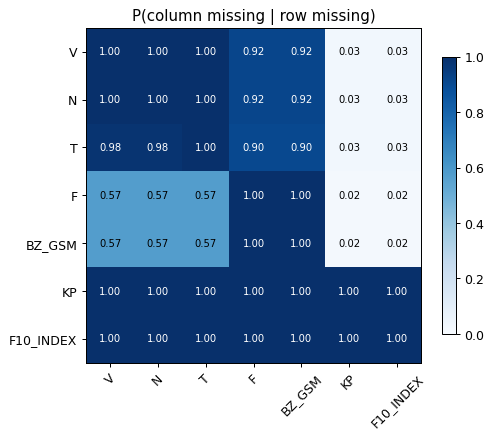

hours with ANY variable missing: 822 (4.7%)
hours with ALL plasma+IMF missing: 444


In [4]:
miss = df[VARIABLES].isna()
co = (miss.T.astype(int) @ miss.astype(int)).div(miss.sum(), axis=0)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(co, vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(len(VARIABLES)), VARIABLES, rotation=45)
ax.set_yticks(range(len(VARIABLES)), VARIABLES)
for i in range(len(VARIABLES)):
    for j in range(len(VARIABLES)):
        ax.text(j, i, f"{co.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if co.iloc[i, j] > 0.6 else "black")
ax.grid(False)
ax.set_title("P(column missing | row missing)")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

print("hours with ANY variable missing:", miss.any(axis=1).sum(),
      f"({100 * miss.any(axis=1).mean():.1f}%)")
print("hours with ALL plasma+IMF missing:", miss[["V", "N", "T", "F", "BZ_GSM"]].all(axis=1).sum())

### 1.3 Gap lengths
Short gaps can be interpolated; long gaps break input windows and need explicit handling.
OMNI also pads the end of the dataset with fill rows before data arrives, so the newest
valid hour is earlier than the inventory end.

In [5]:
def gap_runs(mask):
    m = mask.to_numpy().astype(int)
    edges = np.diff(np.r_[0, m, 0])
    starts, ends = np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)
    return pd.DataFrame(
        {"start": mask.index[starts], "end": mask.index[ends - 1], "hours": ends - starts}
    )


gaps = {v: gap_runs(miss[v]) for v in VARIABLES}
gap_summary = pd.DataFrame(
    {
        v: {
            "gaps": len(g),
            "median h": g["hours"].median() if len(g) else 0,
            "max h": g["hours"].max() if len(g) else 0,
            "% gaps <= 3 h": 100 * (g["hours"] <= 3).mean() if len(g) else np.nan,
            "% missing hours in gaps > 24 h": 100 * g.loc[g["hours"] > 24, "hours"].sum()
            / max(g["hours"].sum(), 1),
        }
        for v, g in gaps.items()
    }
).T
gap_summary

,gaps,median h,max h,% gaps <= 3 h,% missing hours in gaps > 24 h
V,50.0,3.5,86.0,50.00,41.32
N,50.0,3.5,86.0,50.00,41.32
T,58.0,3.0,86.0,56.90,40.65
F,37.0,7.0,397.0,32.43,66.02
BZ_GSM,37.0,7.0,397.0,32.43,66.02
KP,1.0,15.0,15.0,0.00,0.00
F10_INDEX,1.0,15.0,15.0,0.00,0.00


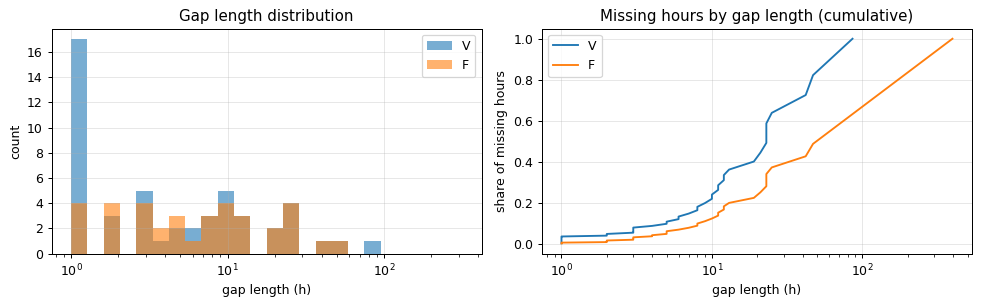

,last valid,trailing fill (h),share of missing hours
V,2026-10-13 00:00:00+00:00,86.0,0.18
N,2026-10-13 00:00:00+00:00,86.0,0.18
T,2026-10-13 00:00:00+00:00,86.0,0.17
F,2026-09-30 01:00:00+00:00,397.0,0.51
BZ_GSM,2026-09-30 01:00:00+00:00,397.0,0.51
KP,2026-10-15 23:00:00+00:00,15.0,1.00
F10_INDEX,2026-10-15 23:00:00+00:00,15.0,1.00


Longest V gaps:


,start,end,hours
0,2026-10-13 01:00:00+00:00,2026-10-16 14:00:00+00:00,86
1,2026-07-24 17:00:00+00:00,2026-07-26 15:00:00+00:00,47
2,2026-08-03 03:00:00+00:00,2026-08-04 20:00:00+00:00,42
3,2026-08-05 22:00:00+00:00,2026-08-06 22:00:00+00:00,25
4,2026-07-28 16:00:00+00:00,2026-07-29 14:00:00+00:00,23
5,2026-07-30 18:00:00+00:00,2026-07-31 16:00:00+00:00,23
6,2026-08-17 16:00:00+00:00,2026-08-18 14:00:00+00:00,23
7,2026-08-15 02:00:00+00:00,2026-08-15 22:00:00+00:00,21
8,2026-01-29 22:00:00+00:00,2026-01-30 16:00:00+00:00,19
9,2026-09-20 02:00:00+00:00,2026-09-20 14:00:00+00:00,13


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for v in ["V", "F"]:
    axes[0].hist(gaps[v]["hours"], bins=np.logspace(0, 2.5, 25), alpha=0.6, label=v)
axes[0].set_xscale("log")
axes[0].set_xlabel("gap length (h)")
axes[0].set_ylabel("count")
axes[0].set_title("Gap length distribution")
axes[0].legend()

for v in ["V", "F"]:
    g = gaps[v].sort_values("hours")
    axes[1].plot(g["hours"].to_numpy(), g["hours"].cumsum() / g["hours"].sum(), label=v)
axes[1].set_xscale("log")
axes[1].set_xlabel("gap length (h)")
axes[1].set_ylabel("share of missing hours")
axes[1].set_title("Missing hours by gap length (cumulative)")
axes[1].legend()
plt.tight_layout()
plt.show()

trailing = pd.DataFrame(
    {
        "last valid": {v: df[v].last_valid_index() for v in VARIABLES},
        "trailing fill (h)": {
            v: (df.index[-1] - df[v].last_valid_index()) / pd.Timedelta(hours=1) for v in VARIABLES
        },
    }
)
trailing["share of missing hours"] = trailing["trailing fill (h)"] / status["missing"]
display(trailing)
print("Longest V gaps:")
gaps["V"].nlargest(10, "hours").reset_index(drop=True)

### 1.4 Missingness over time
Percent of hours missing per variable and calendar month.

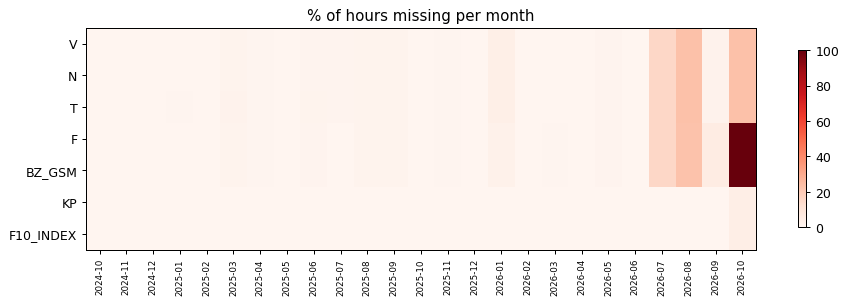

worst months for V (% missing):


Time
2026-10-01 00:00:00+00:00    22.9
2026-08-01 00:00:00+00:00    22.8
2026-07-01 00:00:00+00:00    15.5
2026-01-01 00:00:00+00:00     3.8
2026-09-01 00:00:00+00:00     1.8
Name: V, dtype: float64

In [7]:
monthly = (miss.resample("MS").mean() * 100).T
fig, ax = plt.subplots(figsize=(12, 3.2))
im = ax.imshow(monthly, aspect="auto", cmap="Reds", vmin=0, vmax=max(10, monthly.to_numpy().max()))
ax.set_yticks(range(len(VARIABLES)), VARIABLES)
ax.set_xticks(range(len(monthly.columns)), [c.strftime("%Y-%m") for c in monthly.columns],
              rotation=90, fontsize=7)
ax.grid(False)
ax.set_title("% of hours missing per month")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()
print("worst months for V (% missing):")
monthly.loc["V"].nlargest(5).round(1)

### 1.5 Value ranges and outliers
Valid ranges are the CDAWeb `VALIDMIN`/`VALIDMAX` attributes. Nothing was flagged, so the
question is whether the distributions look physical.

In [8]:
valid = {"V": (0, 1200), "N": (0, 150), "T": (0, 9_999_980), "F": (0, 100),
         "BZ_GSM": (-99.9, 99.9), "Kp": (0, 9), "F10_INDEX": (30, 500)}
desc = df[FEATURES].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).T
desc["valid min"] = [valid[v][0] for v in desc.index]
desc["valid max"] = [valid[v][1] for v in desc.index]
desc["skew"] = df[FEATURES].skew()
desc

,count,mean,std,min,1%,5%,50%,95%,99%,max,valid min,valid max,skew
V,17037.0,466.84,106.91,264.0,293.00,325.0,444.0,673.00,757.64,1.12e+03,0.0,1.20e+03,0.96
N,17037.0,6.15,5.21,0.1,1.00,1.8,4.6,15.70,28.00,7.03e+01,0.0,1.50e+02,3.20
T,17029.0,120663.58,113526.00,3221.0,12364.16,20574.8,90988.0,320635.60,475003.00,4.67e+06,0.0,1.00e+07,7.13
F,16747.0,6.42,3.39,0.5,2.00,2.9,5.7,12.40,18.00,6.38e+01,0.0,1.00e+02,3.32
BZ_GSM,16747.0,-0.06,3.49,-32.6,-9.10,-5.3,-0.1,5.17,9.60,5.89e+01,-99.9,9.99e+01,0.83
Kp,17506.0,2.29,1.36,0.0,0.00,0.3,2.0,4.70,6.00,8.70e+00,0.0,9.00e+00,0.67
F10_INDEX,17506.0,148.94,34.44,91.9,94.10,105.4,145.6,216.40,252.10,3.22e+02,30.0,5.00e+02,1.03


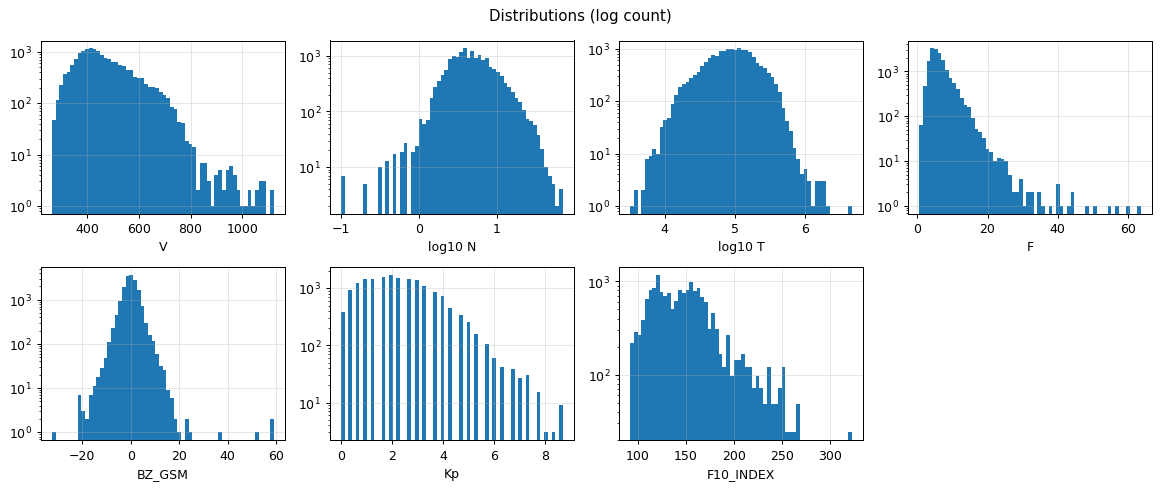

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5))
for ax, v in zip(axes.ravel()[: len(FEATURES)], FEATURES, strict=True):
    x = df[v].dropna()
    if v in ("N", "T"):
        ax.hist(np.log10(x[x > 0]), bins=60)
        ax.set_xlabel(f"log10 {v}")
    else:
        ax.hist(x, bins=60)
        ax.set_xlabel(v)
    ax.set_yscale("log")
axes.flat[-1].axis("off")
fig.suptitle("Distributions (log count)")
plt.tight_layout()
plt.show()

### 1.6 How much history is usable for training?
A training sample at time *t* needs an input window ending at *t* and a target window
V(*t*+1 h … *t*+72 h). Fraction of hours where both windows are complete (no gaps):

In [10]:
def complete_fraction(cols, back, fwd=72):
    ok_in = df[cols].notna().all(axis=1).astype(int)
    past = ok_in.rolling(back).sum() == back
    v_ok = df["V"].notna().astype(int)
    future = (v_ok[::-1].rolling(fwd).sum()[::-1].shift(-1) == fwd)
    return 100 * (past & future).mean()


usable = pd.DataFrame(
    {
        f"{back} h input": {
            "V only": complete_fraction(["V"], back),
            "plasma (V,N,T)": complete_fraction(["V", "N", "T"], back),
            "plasma + IMF": complete_fraction(["V", "N", "T", "F", "BZ_GSM"], back),
        }
        for back in (24, 72)
    }
)
usable.round(1).astype(str) + " %"

,24 h input,72 h input
V only,80.4 %,74.0 %
"plasma (V,N,T)",79.5 %,71.8 %
plasma + IMF,77.5 %,69.0 %


## 2. Time-series properties

### 2.1 The series

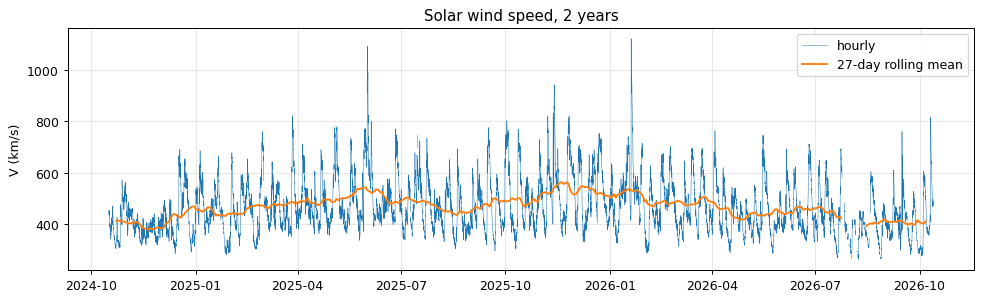

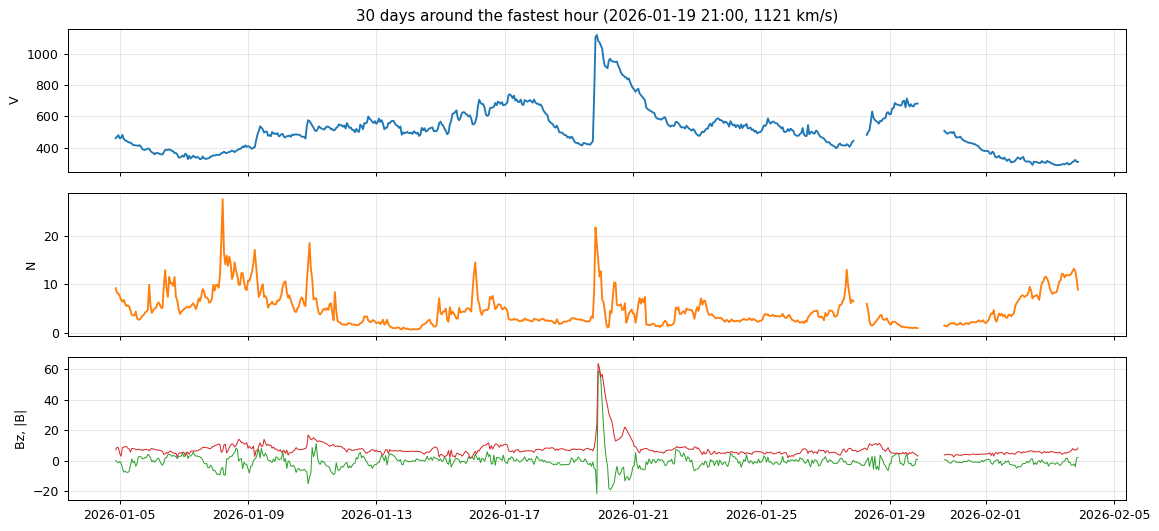

In [11]:
V = df["V"]
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(V.index, V, lw=0.4, label="hourly")
ax.plot(V.index, V.rolling(27 * 24, center=True, min_periods=24 * 20).mean(), lw=1.5,
        label="27-day rolling mean")
ax.set_ylabel("V (km/s)")
ax.set_title("Solar wind speed, 2 years")
ax.legend(loc="upper right")
plt.show()

peak = V.idxmax()
win = df.loc[peak - pd.Timedelta(days=15): peak + pd.Timedelta(days=15)]
fig, axes = plt.subplots(3, 1, figsize=(13, 6), sharex=True)
axes[0].plot(win.index, win["V"])
axes[0].set_ylabel("V")
axes[1].plot(win.index, win["N"], color="C1")
axes[1].set_ylabel("N")
axes[2].plot(win.index, win["BZ_GSM"], color="C2", lw=0.8)
axes[2].plot(win.index, win["F"], color="C3", lw=0.8)
axes[2].set_ylabel("Bz, |B|")
axes[0].set_title(f"30 days around the fastest hour ({peak:%Y-%m-%d %H:%M}, {V.max():.0f} km/s)")
plt.tight_layout()
plt.show()

### 2.2 Distribution of V and of its changes

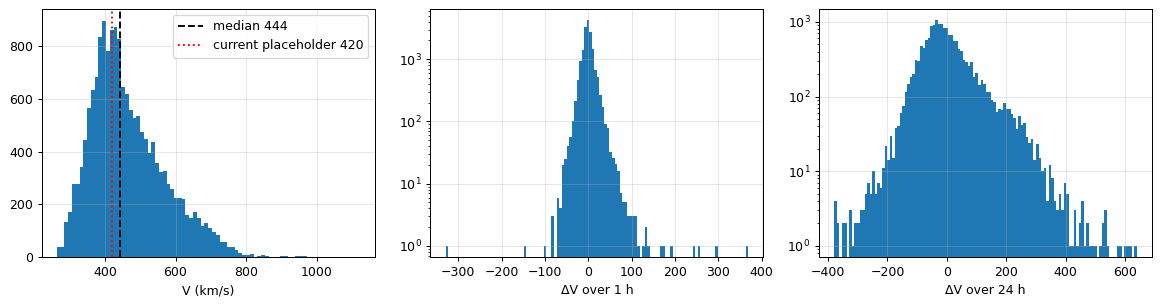

,count,mean,std,min,1%,50%,99%,max,skew,kurtosis
ΔV 1 h,16987.0,0.03,15.85,-329.0,-38.00,-1.0,47.0,369.0,1.97,50.57
ΔV 24 h,16706.0,0.58,89.68,-379.0,-172.95,-15.0,287.0,640.0,1.18,3.61


24 h rises > +150 km/s: 1075 h
24 h drops < -150 km/s: 290 h
share of hours with V > 500 km/s (fast wind): 30.9%


In [12]:
d1, d24 = V.diff(1), V.diff(24)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(V.dropna(), bins=80)
axes[0].axvline(V.median(), color="k", ls="--", label=f"median {V.median():.0f}")
axes[0].axvline(420, color="r", ls=":", label="current placeholder 420")
axes[0].set_xlabel("V (km/s)")
axes[0].legend()
axes[1].hist(d1.dropna(), bins=120)
axes[1].set_yscale("log")
axes[1].set_xlabel("ΔV over 1 h")
axes[2].hist(d24.dropna(), bins=120)
axes[2].set_yscale("log")
axes[2].set_xlabel("ΔV over 24 h")
plt.tight_layout()
plt.show()

changes = pd.DataFrame(
    {
        "ΔV 1 h": d1.describe(percentiles=[0.01, 0.99]),
        "ΔV 24 h": d24.describe(percentiles=[0.01, 0.99]),
    }
).T
changes["skew"] = [d1.skew(), d24.skew()]
changes["kurtosis"] = [d1.kurt(), d24.kurt()]
display(changes)
print(f"24 h rises > +150 km/s: {(d24 > 150).sum()} h")
print(f"24 h drops < -150 km/s: {(d24 < -150).sum()} h")
print(f"share of hours with V > 500 km/s (fast wind): {100 * (V > 500).mean():.1f}%")

### 2.3 Autocorrelation and the 27-day recurrence
Coronal holes rotate with the Sun (synodic period ≈ 27.27 days ≈ 655 h), so fast streams tend to
recur. The ACF is computed with gaps excluded pairwise (`missing="conservative"`).

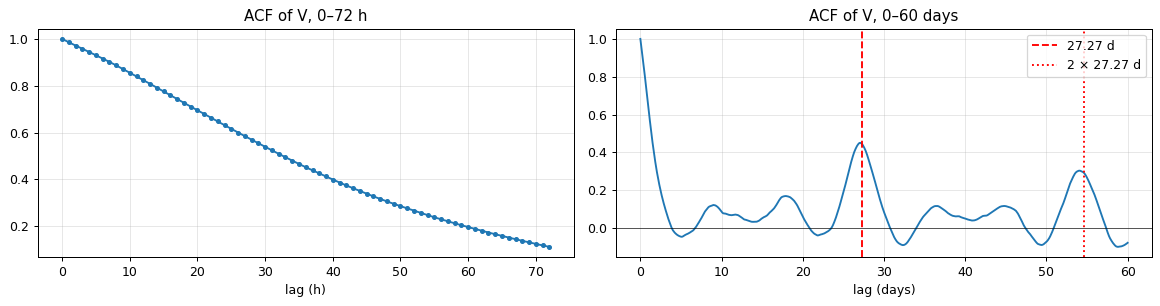

ACF at 1, 6, 24, 48, 72 h: {1: 0.985, 6: 0.916, 24: 0.632, 48: 0.306, 72: 0.112}
lag where ACF first drops below 0.5: 33 h
recurrence peak: lag 649 h (27.04 d), ACF 0.451
ACF minimum within 0–20 d: -0.045 at 5.1 d


In [13]:
ROT = 655
acf_long = acf(V.to_numpy(), nlags=60 * 24, missing="conservative", fft=False)
lags_d = np.arange(len(acf_long)) / 24

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].plot(np.arange(73), acf_long[:73], marker=".")
axes[0].set_xlabel("lag (h)")
axes[0].set_title("ACF of V, 0–72 h")
axes[1].plot(lags_d, acf_long)
axes[1].axvline(ROT / 24, color="r", ls="--", label="27.27 d")
axes[1].axvline(2 * ROT / 24, color="r", ls=":", label="2 × 27.27 d")
axes[1].axhline(0, color="k", lw=0.5)
axes[1].set_xlabel("lag (days)")
axes[1].set_title("ACF of V, 0–60 days")
axes[1].legend()
plt.tight_layout()
plt.show()

window = (lags_d >= 20) & (lags_d <= 35)
peak_lag = np.flatnonzero(window)[np.argmax(acf_long[window])]
print("ACF at 1, 6, 24, 48, 72 h:", {h: round(float(acf_long[h]), 3) for h in (1, 6, 24, 48, 72)})
print(f"lag where ACF first drops below 0.5: {np.argmax(acf_long < 0.5)} h")
print(f"recurrence peak: lag {peak_lag} h ({peak_lag / 24:.2f} d), ACF {acf_long[peak_lag]:.3f}")
early = acf_long[: 20 * 24]
print(f"ACF minimum within 0–20 d: {early.min():.3f} at {early.argmin() / 24:.1f} d")

### 2.4 Partial autocorrelation and stationarity
PACF and the tests need a gap-free series, so gaps are linearly interpolated **for this section only**.

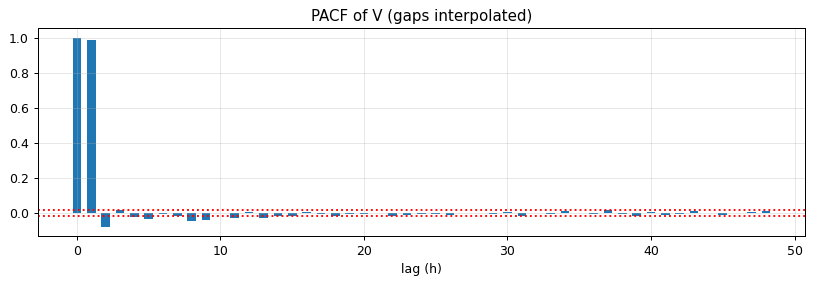

PACF lag1 0.989, lag2 -0.079, lag3 0.017
ADF  stat -12.17, p = 0.0000  (H0: unit root)
KPSS stat 1.27, p = 0.010  (H0: level-stationary)
  note: statsmodels clips the KPSS p-value to [0.01, 0.1]


In [14]:
V_filled = V.interpolate(method="time", limit_direction="both")
pacf_v = pacf(V_filled.to_numpy(), nlags=48)
fig, ax = plt.subplots(figsize=(11, 3))
ax.bar(np.arange(49), pacf_v, width=0.6)
ax.axhline(1.96 / np.sqrt(len(V_filled)), color="r", ls=":")
ax.axhline(-1.96 / np.sqrt(len(V_filled)), color="r", ls=":")
ax.set_xlabel("lag (h)")
ax.set_title("PACF of V (gaps interpolated)")
plt.show()

adf_stat, adf_p, *_ = adfuller(V_filled, maxlag=48, autolag=None)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    kpss_stat, kpss_p, *_ = kpss(V_filled, regression="c", nlags=48)
print(f"PACF lag1 {pacf_v[1]:.3f}, lag2 {pacf_v[2]:.3f}, lag3 {pacf_v[3]:.3f}")
print(f"ADF  stat {adf_stat:.2f}, p = {adf_p:.4f}  (H0: unit root)")
print(f"KPSS stat {kpss_stat:.2f}, p = {kpss_p:.3f}  (H0: level-stationary)")
print("  note: statsmodels clips the KPSS p-value to [0.01, 0.1]")

### 2.5 Decomposition at the solar rotation period
STL on **daily means** with period 27 days (hourly STL at period 655 is slow and adds nothing here).

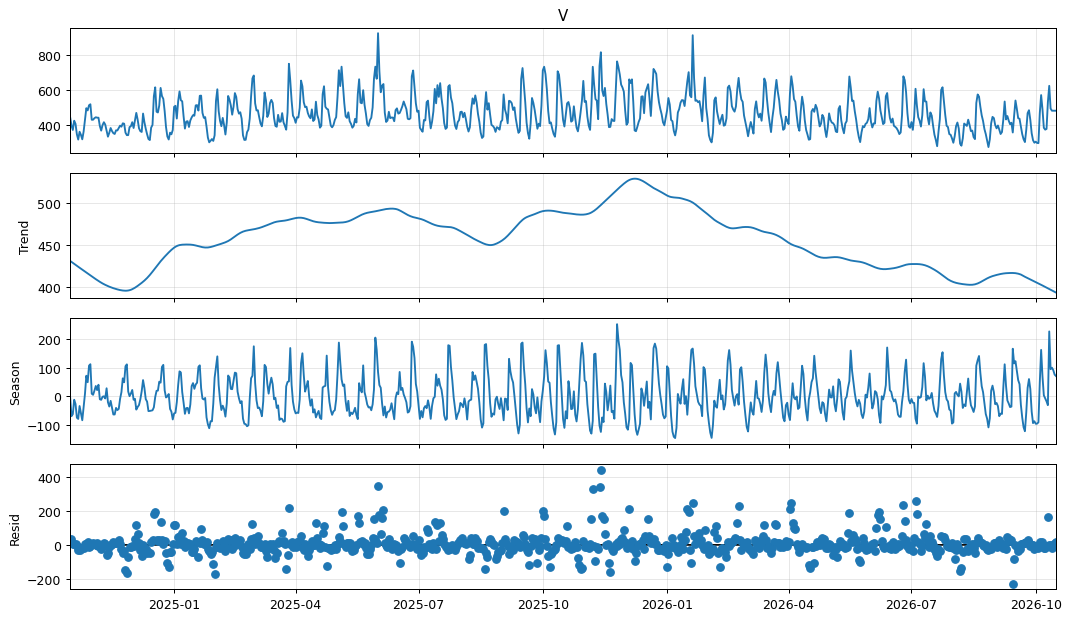

variance share of daily V: {'trend': '12%', 'seasonal': '50%', 'resid': '42%'}


In [15]:
V_daily = V.resample("D").mean().interpolate(limit_direction="both")
stl = STL(V_daily, period=27, robust=True).fit()
fig = stl.plot()
fig.set_size_inches(12, 7)
plt.tight_layout()
plt.show()

var_total = np.var(V_daily - V_daily.mean())
shares = {k: np.var(getattr(stl, k)) / var_total for k in ("trend", "seasonal", "resid")}
print("variance share of daily V:", {k: f"{v:.0%}" for k, v in shares.items()})

### 2.6 Diurnal and annual patterns
A diurnal cycle would point to a processing artefact; none is expected. The monthly means show slow drifts across the solar cycle.

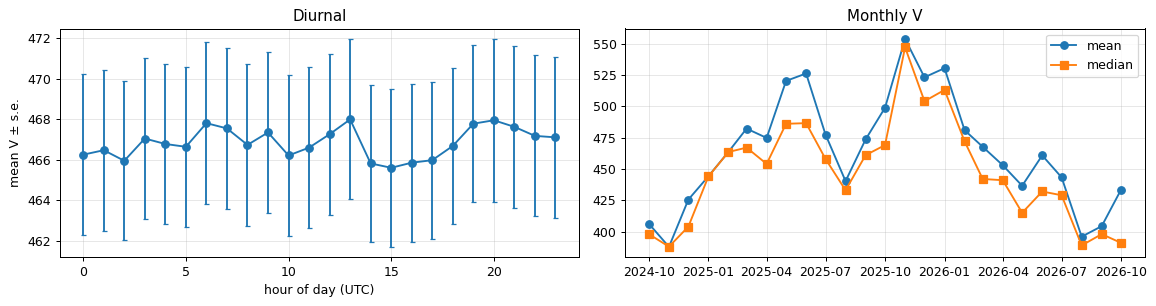

diurnal range of hourly means: 2.4 km/s


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
by_hour = V.groupby(V.index.hour).agg(["mean", "std"])
axes[0].errorbar(by_hour.index, by_hour["mean"], yerr=by_hour["std"] / np.sqrt(len(V) / 24),
                 marker="o", capsize=2)
axes[0].set_xlabel("hour of day (UTC)")
axes[0].set_ylabel("mean V ± s.e.")
axes[0].set_title("Diurnal")
monthly_v = V.resample("MS").agg(["mean", "median"])
axes[1].plot(monthly_v.index, monthly_v["mean"], marker="o", label="mean")
axes[1].plot(monthly_v.index, monthly_v["median"], marker="s", label="median")
axes[1].set_title("Monthly V")
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"diurnal range of hourly means: {by_hour['mean'].max() - by_hour['mean'].min():.1f} km/s")

### 2.7 Baselines over the forecast horizon
Every baseline predicts V(*t*+*h*) for *h* = 1…72 h from information available at *t*:

- **placeholder**: constant 420 km/s (the current submission)
- **climatology**: training-year mean
- **persistence**: V(*t*)
- **recurrence**: V(*t* + *h* − 655 h), the value one solar rotation earlier
- **blend**: *w*(*h*)·persistence + (1 − *w*(*h*))·recurrence, with *w* fitted per horizon on year 1

Weights and climatology are fitted on the **first year**, and every score is computed on the **second year**.

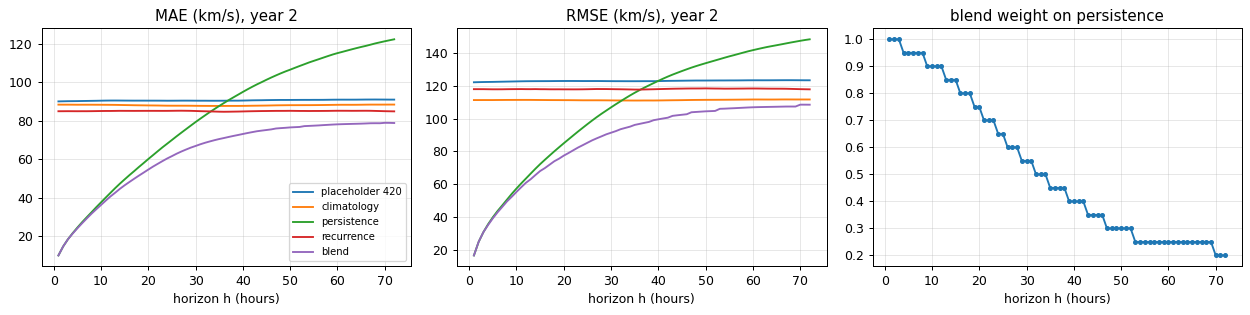

method,blend,climatology,persistence,placeholder 420,recurrence
h,,,,,
1,10.1,88.3,10.1,90.0,84.9
6,26.8,88.3,27.3,90.2,84.9
12,40.7,88.2,42.6,90.5,85.0
24,60.4,87.8,68.1,90.4,85.1
48,76.1,88.0,104.6,90.8,85.1
72,78.8,88.4,122.2,90.9,84.8


mean MAE over 1–72 h: {'blend': 62.7, 'climatology': 88.0, 'persistence': 82.0, 'placeholder 420': 90.6, 'recurrence': 85.0}
mean RMSE over 1–72 h: {'blend': 87.1, 'climatology': 111.4, 'persistence': 106.9, 'placeholder 420': 123.1, 'recurrence': 118.1}
blend weight on persistence: {1: 1.0, 6: 0.95, 24: 0.65, 48: 0.3, 72: 0.2}
recurrence beats persistence from h = 34


In [17]:
H = np.arange(1, 73)
split = df.index[0] + pd.Timedelta(days=365)
train, test = df.index < split, df.index >= split
clim = V[train].mean()


def recurrence(h):
    return V.shift(ROT - h)


def fit_weight(h):
    y, p, r = V.shift(-h)[train], V[train], recurrence(h)[train]
    m = y.notna() & p.notna() & r.notna()
    ws = np.linspace(0, 1, 21)
    return ws[np.argmin([((w * p[m] + (1 - w) * r[m] - y[m]).abs()).mean() for w in ws])]


weights = pd.Series({h: fit_weight(h) for h in H})
preds = {
    "placeholder 420": lambda h: pd.Series(420.0, index=V.index),
    "climatology": lambda h: pd.Series(clim, index=V.index),
    "persistence": lambda h: V,
    "recurrence": recurrence,
    "blend": lambda h: weights[h] * V + (1 - weights[h]) * recurrence(h),
}

rows = []
for h in H:
    y = V.shift(-h)
    # Same evaluation rows for every method: target and all predictors present
    m = test & y.notna() & V.notna() & recurrence(h).notna()
    for name, fn in preds.items():
        e = fn(h)[m] - y[m]
        rows.append({"h": h, "method": name, "MAE": e.abs().mean(), "RMSE": np.sqrt((e**2).mean())})
scores = pd.DataFrame(rows).pivot(index="h", columns="method")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for name in preds:
    axes[0].plot(H, scores["MAE"][name], label=name)
    axes[1].plot(H, scores["RMSE"][name], label=name)
axes[0].set_title("MAE (km/s), year 2")
axes[1].set_title("RMSE (km/s), year 2")
for ax in axes[:2]:
    ax.set_xlabel("horizon h (hours)")
axes[0].legend(fontsize=8)
axes[2].plot(H, weights, marker=".")
axes[2].set_title("blend weight on persistence")
axes[2].set_xlabel("horizon h (hours)")
plt.tight_layout()
plt.show()

display(scores["MAE"].loc[[1, 6, 12, 24, 48, 72]].round(1))
print("mean MAE over 1–72 h:", scores["MAE"].mean().round(1).to_dict())
print("mean RMSE over 1–72 h:", scores["RMSE"].mean().round(1).to_dict())
print("blend weight on persistence:", weights.loc[[1, 6, 24, 48, 72]].round(2).to_dict())
crossover = H[(scores["MAE"]["recurrence"] < scores["MAE"]["persistence"]).to_numpy()]
print("recurrence beats persistence from h =", crossover.min() if len(crossover) else "never")

## 3. Correlations

### 3.1 Between variables at the same time
N and T are log-transformed (both span orders of magnitude). Spearman is rank-based, so the transform only matters for Pearson.

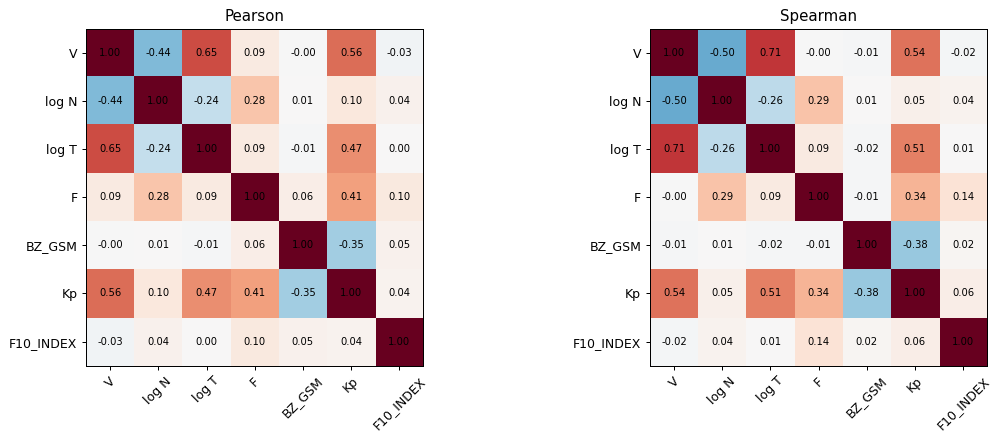

log N       -5.04e-01
F10_INDEX   -1.70e-02
BZ_GSM      -1.28e-02
F           -3.67e-03
Kp           5.41e-01
log T        7.15e-01
Name: V, dtype: float64

In [18]:
X = df[FEATURES].copy()
X["N"], X["T"] = np.log10(X["N"]), np.log10(X["T"])
X = X.rename(columns={"N": "log N", "T": "log T"})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, method in zip(axes, ["pearson", "spearman"], strict=True):
    c = X.corr(method=method)
    ax.imshow(c, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(c)), c.columns, rotation=45)
    ax.set_yticks(range(len(c)), c.columns)
    for i in range(len(c)):
        for j in range(len(c)):
            ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.grid(False)
    ax.set_title(method.capitalize())
plt.tight_layout()
plt.show()
X.corr(method="spearman")["V"].drop("V").sort_values()

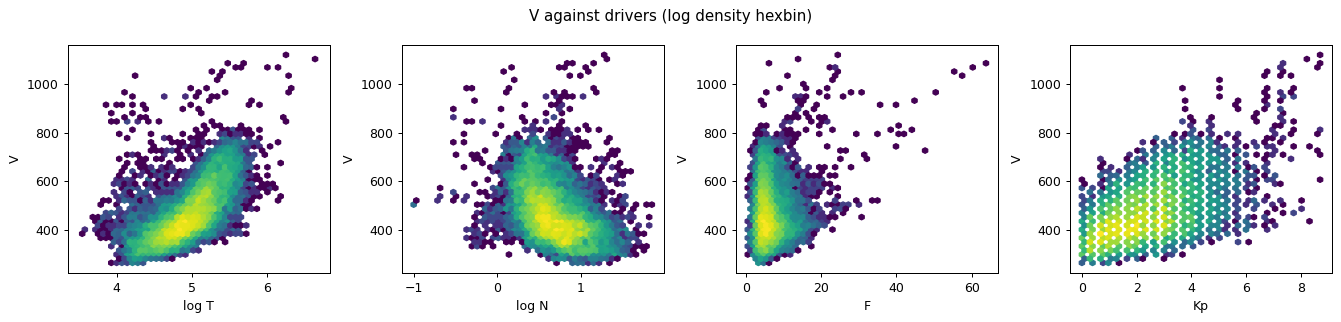

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, col in zip(axes, ["log T", "log N", "F", "Kp"], strict=True):
    m = X["V"].notna() & X[col].notna()
    ax.hexbin(X.loc[m, col], X.loc[m, "V"], gridsize=45, bins="log", cmap="viridis")
    ax.set_xlabel(col)
    ax.set_ylabel("V")
    ax.grid(False)
fig.suptitle("V against drivers (log density hexbin)")
plt.tight_layout()
plt.show()

### 3.2 Lagged correlation: variable at *t* vs V at *t* + *h*
This is the forecasting question: which values available at *t* say something about V up to 72 h ahead?
Spearman correlation per horizon.

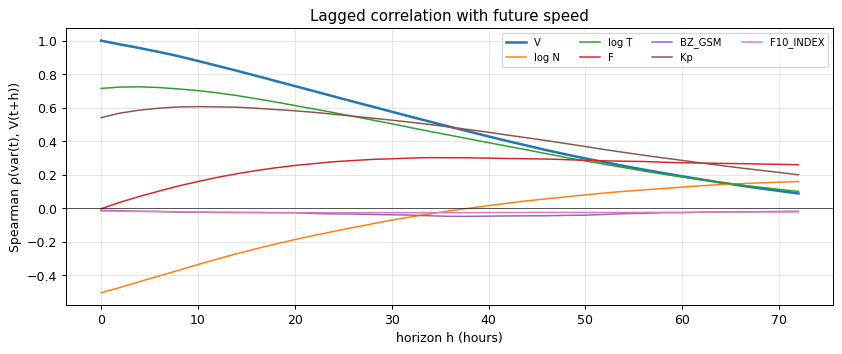

,V,log N,log T,F,BZ_GSM,Kp,F10_INDEX
0,1.00,-0.50,0.71,-0.00,-0.01,0.54,-0.02
12,0.85,-0.30,0.69,0.18,-0.03,0.60,-0.02
24,0.67,-0.14,0.57,0.28,-0.03,0.56,-0.03
48,0.32,0.07,0.30,0.29,-0.04,0.39,-0.03
72,0.09,0.16,0.10,0.26,-0.02,0.20,-0.02


In [20]:
lags = np.arange(0, 73, 2)
xcorr = pd.DataFrame(
    {col: [X[col].corr(X["V"].shift(-h), method="spearman") for h in lags] for col in X.columns},
    index=lags,
)
fig, ax = plt.subplots(figsize=(11, 4))
for col in xcorr.columns:
    ax.plot(lags, xcorr[col], label=col, lw=2 if col == "V" else 1.2)
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("horizon h (hours)")
ax.set_ylabel("Spearman ρ(var(t), V(t+h))")
ax.legend(ncol=4, fontsize=8)
ax.set_title("Lagged correlation with future speed")
plt.show()
xcorr.loc[[0, 12, 24, 48, 72]].round(2)

### 3.3 Do the drivers predict the *change* in V?
Persistence already captures the level of V. The useful extra signal is whether a variable at *t*
predicts V(*t*+*h*) − V(*t*). An example is compressed, dense, strong-field plasma ahead of an arriving fast stream.

In [21]:
dchange = pd.DataFrame(
    {
        f"ΔV {h} h": {col: X[col].corr(X["V"].shift(-h) - X["V"], method="spearman")
                      for col in X.columns}
        for h in (6, 24, 48, 72)
    }
)
display(dchange.round(2))

# Rate of change of density and field as a stream-interaction signature
signals = pd.DataFrame(
    {
        "dlogN/24h": X["log N"].diff(24),
        "dF/24h": X["F"].diff(24),
        "dV/24h (past)": X["V"].diff(24),
    }
)
pd.DataFrame(
    {
        f"ΔV {h} h": {c: signals[c].corr(X["V"].shift(-h) - X["V"], method="spearman")
                      for c in signals}
        for h in (6, 24, 48, 72)
    }
).round(2)

,ΔV 6 h,ΔV 24 h,ΔV 48 h,ΔV 72 h
V,-0.24,-0.46,-0.61,-0.69
log N,0.30,0.49,0.51,0.50
log T,0.00,-0.19,-0.37,-0.47
F,0.30,0.38,0.28,0.19
BZ_GSM,-0.02,-0.03,-0.03,-0.00
Kp,0.10,-0.02,-0.17,-0.28
F10_INDEX,-0.01,-0.00,0.01,0.00


,ΔV 6 h,ΔV 24 h,ΔV 48 h,ΔV 72 h
dlogN/24h,0.11,0.22,0.25,0.28
dF/24h,0.21,0.32,0.27,0.24
dV/24h (past),0.10,0.07,-0.05,-0.11


## 4. Findings

Window: 2024-10-16 14:00 → 2026-10-16 14:00 UTC, 17,521 hourly rows. Baseline scores are on the second year only.

### (i) Data quality
- **Values are clean.** No value is flagged. Everything sits inside CDAWeb's valid ranges, and the distributions look physical. N, T and |B| have long right tails (skew 3.2, 7.1, 3.3), so work with log N and log T.
- **Missing data is low and comes in instrument groups.**
  - V and N: 2.8% missing; T: 2.8%.
  - F and Bz: 4.4%.
  - Kp and F10.7: 0.1%, all of it at the very end of the window.
  - Plasma gaps (V, N, T) coincide with each other, and so do magnetic field gaps (F, Bz). In 444 hours both groups are out at once.
- **OMNI pads its newest data with fill values.**
  - The last valid V is 2026-10-13 00:00, 86 h before the inventory end.
  - The last valid F and Bz is 2026-09-30 01:00, about 16.5 days before it. That one run is roughly half of all missing magnetic field hours.
  - The inventory end overstates how fresh OMNI is.
- **Gaps are mostly short, apart from mid-2026.**
  - Half of V gaps last 3 h or less (median 3.5 h).
  - Before July 2026 the record is nearly complete. July–August 2026 has a cluster of 1–2-day outages, with 15–23% of hours missing in those months. Their cause isn't established here.
- **Short gaps cost a lot of training samples.** Each gap removes every sample whose input or 72 h target window touches it. With no gap filling, only 80% of hours are usable as samples (24 h of V input), 74% with 72 h of input, and 69% with 72 h of plasma and magnetic field input.

### (ii) Time-series properties
- **Level:** mean 467 km/s, median 444, range 264–1121, right-skewed. 31% of hours are fast wind (> 500 km/s). The current 420 km/s placeholder sits below the median.
- **Strong but short memory.**
  - ACF is 0.985 at 1 h, 0.63 at 24 h, 0.31 at 48 h and 0.11 at 72 h, and drops below 0.5 at 33 h.
  - The PACF is almost purely AR(1) (lag 1 0.989, lag 2 −0.08), so most short-range information is in the latest value.
- **Speed rises fast and decays slowly.**
  - Hour-to-hour changes are extremely heavy-tailed (kurtosis 51: shocks and stream interfaces).
  - Over 24 h, rises above +150 km/s occur in 1,075 h but drops of the same size in only 290 h. The median 24 h change is −15 km/s.
  - A model has to anticipate sudden rises, and decay is the default.
- **27-day solar rotation recurrence.**
  - The ACF has a clear secondary peak of 0.45 at 27.0 days, and another near 54.5 days.
  - On daily means, the 27-day seasonal component carries 50% of the variance, slow trend 12% and residual 42%.
- **Stationarity:** ADF rejects a unit root (p < 0.001), but KPSS rejects level-stationarity (p ≤ 0.01). V is mean-reverting around a slowly drifting level (27-day mean 380–560 km/s), so no differencing is needed, but the slow level matters.
- **No diurnal cycle** (hourly means vary by 2.4 km/s), so there's no reason for time-of-day features.
- **Baselines to beat (year 2, MAE in km/s):**

  | | 1 h | 24 h | 48 h | 72 h | mean 1–72 h (MAE / RMSE) |
  |---|---|---|---|---|---|
  | placeholder 420 | 90 | 90 | 91 | 91 | 90.6 / 123.1 |
  | climatology | 88 | 88 | 88 | 88 | 88.0 / 111.4 |
  | persistence | 10 | 68 | 105 | 122 | 82.0 / 106.9 |
  | 27-day recurrence | 85 | 85 | 85 | 85 | 85.0 / 118.1 |
  | **persistence/recurrence blend** | **10** | **60** | **76** | **79** | **62.7 / 87.1** |

  Recurrence overtakes persistence from 34 h. The blend's weight on persistence falls from 1.0 at 1 h to 0.65 at 24 h and 0.2 at 72 h. The blend is the bar any model must clear.

### (iii) Correlations
- **Same-time relationships** (Spearman with V): log T +0.72, Kp +0.54, log N −0.50. |B|, Bz and F10.7 are near zero. This matches known physics: fast wind is hot and tenuous.
- **Lagged relationships, variable at *t* vs V at *t* + *h*:**
  - V's own correlation fades from 0.85 at 12 h to 0.09 at 72 h.
  - **|B| goes from 0.00 at 0 h to about +0.28 at 24–48 h**, and **log N flips from −0.50 to +0.16 at 72 h**. This is the stream-interaction signature: compressed, dense, strong-field plasma arrives ahead of a fast stream.
  - Kp keeps +0.39 at 48 h.
- **Predicting the change ΔV = V(*t*+*h*) − V(*t*):**
  - log N at *t* correlates +0.49 to +0.51 with ΔV over 24–72 h, and |B| +0.38 at 24 h.
  - V itself correlates −0.69 at 72 h (mean reversion), and log T −0.47 at 72 h.
  - 24 h changes in log N and |B| add +0.2 to +0.3.
  - These are the inputs most likely to improve on the baseline blend.
- **Bz and F10.7 carry no signal for speed** at any lag (|ρ| ≤ 0.04). Bz drives geomagnetic response, not wind speed, and F10.7 varies too slowly over 2 years.

### Implications for the next stage
1. **Gaps:** interpolate short gaps (≤ about 3–6 h) and mask longer ones. Record each variable's *last valid* time rather than trusting the inventory end. `pull_omni`'s manifest should report it.
2. **Features:**
   - recent V (latest value plus a few lags or summaries over ≤ 24 h)
   - the recurrence value V(*t* + *h* − 655 h)
   - log N, |B|, log T and Kp levels, plus their 24 h changes
   - leave out Bz and F10.7 to start with
3. **Target and evaluation:** predict all 72 horizons, ideally as a correction to the blend or as ΔV. Evaluate on a held-out final year against the blend (MAE 62.7 / RMSE 87.1).
4. **Live inputs differ from OMNI.**
   - At *t0*, SWPC only provides about the last 24 h of 1-minute L1 data, and it isn't shifted to the bow shock (it leads OMNI by about 30–60 min).
   - OMNI ends 3.5 days to more than 2 weeks before *t0*, depending on the variable.
   - So live features should use at most 24 h of recent history from SWPC, averaged to hourly.
   - The recurrence input needs V from 24–27 days earlier, which OMNI does cover at run time.
   - Training features must be built to match exactly what is available live.